# Case Study: Statistical Metamorphic Testing of a Poisson Line Tessellation Model

This tutorial walks through the first case study (Section 5.1) of our paper
[*Testing Causality in Scientific Modelling Software*](https://dl.acm.org/doi/10.1145/3607184).
We test a small, stochastic scientific model in two ways. First, we use **statistical metamorphic testing** (SMT),
the conventional approach for this kind of model. Then we use the Causal Testing Framework (CTF), and show that it
reaches the same conclusions while using **a fifth of the data**.

By the end of this tutorial you will have:

1. learned what the system under test does, and why it's hard to test;
2. seen how SMT tests the model, and what that costs;
3. written down our assumptions about the system as a **causal DAG**;
4. used the DAG to work out which variables must be controlled for (**identification**);
5. built and run **causal test cases** that estimate causal effects from existing data, and compared them with SMT.

You only need basic familiarity with Python and pandas. We will explain the statistical and causal ideas as we go.

## The system under test: a Poisson Line Tessellation model

The Poisson Line Tessellation (PLT) model from [Guderlei and Mayer (2007)](https://doi.org/10.1145/3695990) scatters straight lines at random positions and orientations over a
rectangular *sampling window*. The lines cut the window into polygons. The model has three inputs:

| Input | Column in data | Meaning |
|---|---|---|
| $W$ | `width` | width of the sampling window |
| $H$ | `height` | height of the sampling window |
| $I$ | `intensity` | intensity of the Poisson process (higher intensities generate more lines) |

It produces four outputs:

| Output | Column in data | Meaning |
|---|---|---|
| $L_t$ | `num_lines_abs` | total number of lines that cross the window |
| $P_t$ | `num_shapes_abs` | total number of polygons formed in the window |
| $L_u$ | `num_lines_unit` | lines per unit area, $L_t / (W \times H)$ |
| $P_u$ | `num_shapes_unit` | polygons per unit area, $P_t / (W \times H)$ |

The source code of the model can be found in `causal_testing.examples.poisson_line_process`.
Let's draw some tessellations to see what they look like.

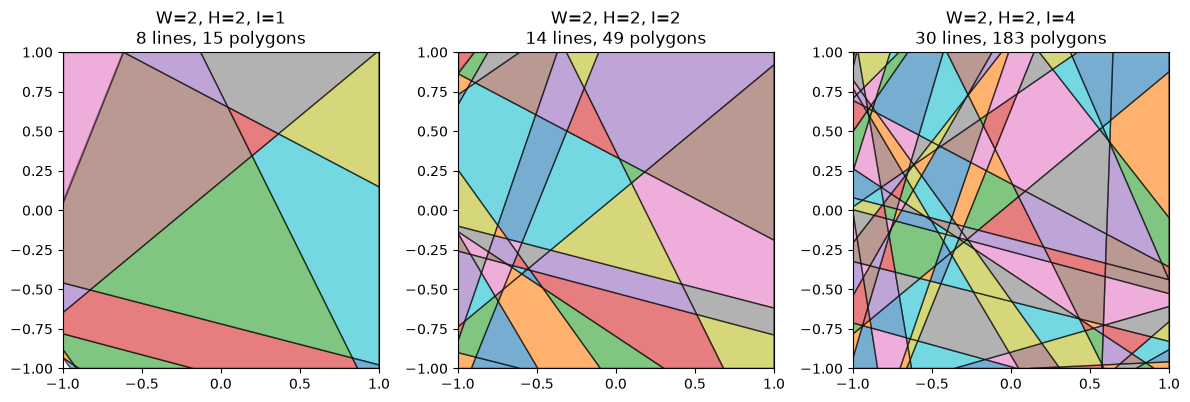

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import uniform

from causal_testing.examples.poisson_line_process.poisson_line_process import (
    detect_shapes,
    realize_poisson_line_process,
)


def draw_tessellation(width, height, intensity, ax, seed=1):
    # Generate the random lines (as slope/intercept pairs) and the polygons they form inside the window.
    np.random.seed(seed)
    lines = realize_poisson_line_process(width, height, intensity, uniform(loc=0, scale=np.pi))
    polygons = detect_shapes(lines, width, height)

    for polygon in polygons:
        # The intersection with the window can occasionally produce multi-part geometries
        for part in getattr(polygon, "geoms", [polygon]):
            if hasattr(part, "exterior"):
                ax.fill(*part.exterior.xy, alpha=0.6, edgecolor="black")
    ax.set_xlim(-width / 2, width / 2)
    ax.set_ylim(-height / 2, height / 2)
    ax.set_aspect("equal")
    ax.set_title(f"W={width}, H={height}, I={intensity}\n{len(lines)} lines, {len(polygons)} polygons")


fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, intensity in zip(axes, [1, 2, 4]):
    draw_tessellation(width=2, height=2, intensity=intensity, ax=ax)
plt.tight_layout()
plt.show()

## Why is this model hard to test?

When testing a conventional software system, we run it on some input and check that the output is correct.
That relies on having a **test oracle**, some way of knowing what the correct output is for a given input in advance of running the system.
For many scientific models, we don't have one:

* **The output is random.** Run the PLT model twice with the same inputs and you'll get a different tessellation, with
  a different number of lines and polygons, each time. There's no single "correct" output to check against. Of course, we can use fixed random seeds, but this isn't very informative of the model's overall behaviour.
* **The exact answer is unknown.** Theory tells us roughly what to expect *on average* (for example, the number of
  polygons per unit area should be about $\pi I^2$), but these are approximations. If the model gave us 3.0 when
  theory said 3.14, we couldn't tell whether that's a bug, random noise, or just the limits of the approximation.

### Metamorphic testing

[**Metamorphic testing**](https://en.wikipedia.org/wiki/Metamorphic_testing) gets around the lack of an oracle.
Instead of checking individual outputs, we check that _changing_ an input in a particular way leads to the expected change in output.
For example, we might not know exactly how many polygons the model should produce, but we do know that increasing the intensity should
produce more. These relationships are called **metamorphic relations**.

A metamorphic test runs the model on a *source* input, makes a specific change to get a *follow-up* input, runs the
model again, and checks that the outputs are related in the expected way.

### Statistical metamorphic testing

Because the PLT model is random, comparing a single source run with a single follow-up run doesn't tell us much. Any
difference could just be chance. **Statistical metamorphic testing** (SMT), introduced by [Guderlei and Mayer (2007)](https://doi.org/10.1145/3695990), deals with this by running the source and follow-up inputs *many times each*, and comparing
the outputs *on average* using statistics.

## The metamorphic relations

In their paper, Guderlei and Mayer define two metamorphic relations to hold for the PLT model:

* **MR1:** Doubling the intensity $I$ should cause the number of polygons per unit area $P_u$ to increase by a factor
  of 4.
* **MR2:** $P_u$ should be independent of the window size, i.e. changing $W$ or $H$ should have no effect on $P_u$.

Both relations come from [theory](https://doi.org/10.1002/9781118658222): $P_u \approx \pi I^2$, so doubling $I$ should multiply $P_u$ by $2^2 = 4$, and should not be affected be $W$ or $H$ at all.

## Testing with SMT

To test these relations, we collect 5000 runs of the PLT model. For each
square window size $W = H \in \{1, 2, \dots, 10\}$ and each intensity $I \in \{1, 2, 4, 8, 16\}$, we ran the model 100 times. These data are included with the CTF.

In [2]:
import pandas as pd

from causal_testing.examples import poisson_line_process as plp

smt_df = plp.smt_df
smt_df

,width,height,intensity,num_lines_abs,num_shapes_abs,num_lines_unit,num_shapes_unit
0,1.0,1.0,1.0,3.0,5.0,3.00,5.00
1,1.0,1.0,2.0,5.0,7.0,5.00,7.00
2,1.0,1.0,4.0,18.0,78.0,18.00,78.00
3,1.0,1.0,8.0,41.0,402.0,41.00,402.00
4,1.0,1.0,16.0,56.0,539.0,56.00,539.00
...,...,...,...,...,...,...,...
4995,10.0,10.0,1.0,37.0,309.0,0.37,3.09
4996,10.0,10.0,2.0,86.0,1692.0,0.86,16.92
4997,10.0,10.0,4.0,173.0,6125.0,1.73,61.25
4998,10.0,10.0,8.0,281.0,15377.0,2.81,153.77


### MR1 with SMT: doubling $I$ should multiply $P_u$ by 4

Since MR1 is about a *multiplicative* change, the natural measure is the **risk ratio** (RR):

$$RR = \frac{\mathbb{E}[P_u \mid I = i_t]}{\mathbb{E}[P_u \mid I = i_c]}$$

Here $\mathbb{E}[\cdot]$ means the *expected* (i.e. average) value, $i_c$ is the source (or *control*) value of intensity, and
$i_t = 2 i_c$ is the follow-up (or *treatment*) value. If MR1 holds, we expect $RR = 4$.

With the SMT data, this is straightforward. The runs were designed so that only $I$ varies within each window size, so
we can simply divide the average $P_u$ at each intensity by the average at half that intensity.

In [3]:
# Average number of polygons per unit area for each (window size, intensity) combination
mean_pu = smt_df.groupby(["width", "intensity"])["num_shapes_unit"].mean().unstack()

intensity_pairs = [(1, 2), (2, 4), (4, 8), (8, 16)]
smt_results = pd.DataFrame(
    {f"I: {control} → {treatment}": mean_pu[treatment] / mean_pu[control] for control, treatment in intensity_pairs}
)
smt_results.index = [f"W = H = {int(w)}" for w in smt_results.index]
smt_results.round(4)

,I: 1 → 2,I: 2 → 4,I: 4 → 8,I: 8 → 16
W = H = 1,2.5888,3.4461,3.6178,3.6187
W = H = 2,3.0359,3.5410,3.6003,3.7264
W = H = 3,3.5025,3.5945,4.0191,3.6545
W = H = 4,3.1138,3.5285,4.1562,3.7290
W = H = 5,3.6686,3.7686,3.9408,3.8751
W = H = 6,3.6933,3.6988,3.9219,3.9707
W = H = 7,3.7127,3.6271,3.9862,3.9370
W = H = 8,3.4957,3.8300,3.8861,4.0110
W = H = 9,3.5633,4.0009,3.9342,3.9338
W = H = 10,3.8275,3.7525,4.0128,4.0181


The above table corresponds to Table 1 in our paper.
If MR1 holds, every value should be close to 4.
Instead, for small windows and low intensities, doubling the intensity multiplies $P_u$ by a factor closer to **3**, so the relation is violated.

### MR2 with SMT: $P_u$ should not depend on window size

In the table above, the violations of MR1 correspond to a small window size.
This seems to contradict MR2, which says $P_u$ shouldn't depend on window size at all.

Here we're not interested in a ratio, just whether there's any change, so we compare the *difference* in average
$P_u$ between neighbouring window sizes, keeping the intensity fixed at $I = 1$. If MR2 holds, this difference should
be zero. To decide whether a difference is real or just random noise, we use a
[t-test](https://en.wikipedia.org/wiki/Welch%27s_t-test), which gives a 95% confidence interval for the difference.
If the interval contains zero, there's no statistically significant difference and the test passes.

In [4]:
from scipy.stats import ttest_ind

smt_intensity_1 = smt_df[smt_df["intensity"] == 1]

smt_mr2_results = []
for size in range(1, 10):
    source = smt_intensity_1.loc[smt_intensity_1["width"] == size, "num_shapes_unit"]
    follow_up = smt_intensity_1.loc[smt_intensity_1["width"] == size + 1, "num_shapes_unit"]
    t_test = ttest_ind(follow_up, source, equal_var=False)
    ci = t_test.confidence_interval(confidence_level=0.95)
    smt_mr2_results.append(
        {
            "W = H": f"{size} → {size + 1}",
            "difference": follow_up.mean() - source.mean(),
            "ci_low": ci.low,
            "ci_high": ci.high,
            "outcome": "PASS" if ci.low <= 0 <= ci.high else "FAIL",
        }
    )

smt_mr2_results = pd.DataFrame(smt_mr2_results).set_index("W = H")
smt_mr2_results.round(4)

,difference,ci_low,ci_high,outcome
W = H,,,,
1 → 2,-1.7825,-3.2131,-0.3519,FAIL
2 → 3,-1.3364,-2.1177,-0.5551,FAIL
3 → 4,0.2820,-0.3113,0.8754,PASS
4 → 5,-0.7619,-1.3108,-0.2131,FAIL
5 → 6,-0.0770,-0.5446,0.3905,PASS
6 → 7,0.0430,-0.3912,0.4771,PASS
7 → 8,0.0477,-0.3728,0.4682,PASS
8 → 9,-0.2856,-0.6730,0.1018,PASS
9 → 10,-0.0958,-0.4296,0.2381,PASS


For windows larger than 5×5 the confidence intervals contain zero, so window size makes no significant difference.
But for the smaller windows (the changes 1 → 2, 2 → 3, and 4 → 5), increasing the window size causes a significant
*decrease* in $P_u$. MR2 is violated for small windows too.

This points to the likely cause of both violations. It comes down to geometry. Lines are less likely to cross a small
window, and a small window has very little area to average over, so $P_u$ behaves differently. The fix is not
necessarily in the code. The metamorphic relations should probably state a **minimum window size** above which they're
expected to hold.

### The cost of SMT

SMT found real problems, but it was expensive:

* It needed **5000 model runs**, 100 for each combination of window size and intensity that we tested.
* Those runs had to be **designed in advance** for a specific relation. Within each group of runs, only the input
  under test could vary. Here we were lucky that the MR1 runs also happened to vary the window size, so we could reuse
  them for MR2. But they only cover *square* windows. To test, say, the effect of the width alone, we'd need to design
  and run a fresh batch of experiments.

For a model that's quick to run, this might be acceptable. For models that take minutes or hours per run, it quickly
becomes impractical.

## Testing with causal testing

**Causal testing** takes a different approach. A metamorphic relation is really a statement about cause and effect:
"*changing* $X$ *causes* $Y$ to change in a certain way". The field of
[causal inference](https://en.wikipedia.org/wiki/Causal_inference) gives us tools to estimate such effects from data
that was *not* collected specifically for the test, such as a set of past model runs where many inputs varied at once.
All we need to do is state our assumptions about the system clearly, so that we avoid being misled by spurious
correlations.

We'll now test the same two relations using the CTF, but this time using a smaller, general-purpose dataset.

### The causal testing workflow

Causal testing with the CTF follows a small number of steps:

1. **Specify the scenario and causal DAG.** Write down the input ranges you're interested in and your
   assumptions about which variables cause which.
2. **Collect data.** Gather runs of the system, ideally ones you already have.
3. **Define causal test cases.** For each metamorphic relation, give the treatment (the input we change), the
   outcome (the output we observe), the change we make, and the effect we expect.
4. **Identification.** Use the DAG to work out which other variables (if any) must be adjusted for so that the
   estimate reflects causation rather than mere correlation.
5. **Estimation.** Fit a statistical model (here, a regression model) to the data to estimate the causal effect.
6. **Apply the test oracle.** Compare the estimated effect against the expected effect to decide whether the test
   passes or fails.

Steps 1 and 2 only need doing once. We then repeat steps 3 to 6 for each metamorphic relation.

## Step 1: The modelling scenario and causal DAG

### Modelling scenario

The *modelling scenario* describes the part of the input space we care about. As in the paper, we restrict ourselves
to square windows no larger than 10×10, with intensity at most 16:

$$\{0 < W \leq 10,\ 0 < I \leq 16,\ W = H\}$$

### Causal DAG

A **causal DAG** (directed acyclic graph) records what we believe about how the system works. Each node is a variable,
and an arrow $X \rightarrow Y$ means "$X$ directly affects $Y$". Just as important, a *missing* arrow is a claim that
there is *no* direct effect. The CTF uses the DAG to work out how to estimate each causal effect correctly.

The DAG for the PLT model is stored in [DOT format](https://graphviz.org/doc/info/lang.html) and is included with the
CTF. Let's load and display it.

digraph G {
width -> num_lines_abs;
width -> num_shapes_abs;
width -> num_lines_unit;
width -> num_shapes_unit;
num_lines_abs -> num_lines_unit;
num_lines_abs -> num_shapes_abs;
num_shapes_abs -> num_shapes_unit;
height -> num_lines_abs;
height -> num_shapes_abs;
height -> num_lines_unit;
height -> num_shapes_unit;
intensity -> num_lines_abs;
}


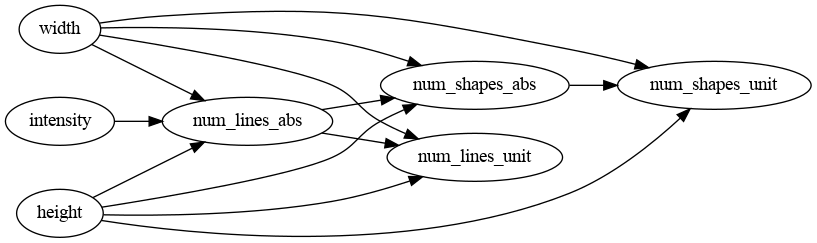

In [5]:
from causal_testing.specification.causal_dag import CausalDAG

from tutorial_utils import render_dag

dag = CausalDAG(plp.dag_path)
print(dag.to_dot_string())
render_dag(dag)

Each arrow comes from domain knowledge about the model:

* **$W$, $H$, $I \rightarrow L_t$**. Theory tells us that $L_t \approx 2I(W + H)$. So all three inputs affect the
  number of lines.
* **$L_t \rightarrow P_t$**. Polygons are formed where lines cross, so the number of polygons depends on the number of
  lines.
* **$W$, $H \rightarrow P_t$**. Theory gives $P_t \approx \pi I^2 W H$, so the window size matters directly.
  We deliberately do **not** draw an arrow $I \rightarrow P_t$. Intensity only affects the polygons *through* the
  lines it creates.
* **$W$, $H \rightarrow L_u, P_u$** and **$L_t \rightarrow L_u$**, **$P_t \rightarrow P_u$**. The per-unit-area outputs
  are computed by dividing the totals by the window area.

Notice that the inputs have no arrows between them. In our data, the inputs are chosen independently, so no input
causes another. Building this DAG took very little effort, because the input/output relationships of the PLT model are
well documented.

## Step 2: The data

Instead of the 5000 purpose-built SMT runs, the CTF uses **1000 runs** of the model with inputs chosen at random using
[Latin hypercube sampling](https://en.wikipedia.org/wiki/Latin_hypercube_sampling) over
$W, H \sim U(0, 10)$ and $I \sim U(0, 16)$. This dataset was *not* designed with any particular metamorphic relation
in mind. All three inputs vary at once in every run. It stands in for the kind of "past execution data" you might
already have lying around. Latin hypercube sampling spreads the runs evenly over the input space, which helps our
statistical models later on.

In [6]:
observational_df = plp.random_df
observational_df

,width,height,intensity,num_lines_abs,num_shapes_abs,num_lines_unit,num_shapes_unit
0,4.908266,8.367783,10.684103,278.0,13991.0,6.768716,340.651464
1,9.239562,0.632306,12.826541,238.0,2603.0,40.737877,445.549133
2,5.144895,9.633530,15.219349,425.0,33859.0,8.574859,683.143879
3,3.489453,4.535775,8.362393,126.0,3305.0,7.960892,208.815469
4,7.985650,1.090290,1.032276,24.0,74.0,2.756506,8.499228
...,...,...,...,...,...,...,...
995,8.198583,2.479352,7.394970,152.0,3378.0,7.477674,166.181475
996,5.539523,9.453742,12.416852,378.0,22500.0,7.217980,429.641692
997,1.182998,4.851435,4.361107,53.0,534.0,9.234678,93.043734
998,2.438737,1.708604,1.107249,6.0,14.0,1.439942,3.359864


We can check that the inputs cover the modelling scenario reasonably evenly:

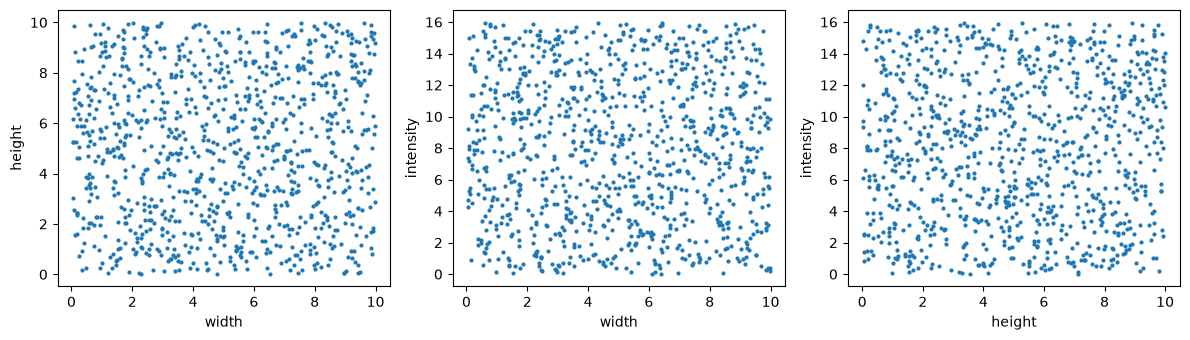

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (x, y) in zip(axes, [("width", "height"), ("width", "intensity"), ("height", "intensity")]):
    ax.scatter(observational_df[x], observational_df[y], s=4)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
plt.tight_layout()
plt.show()

Note that, unlike the modelling scenario, the observational data does **not** always have square windows. The
`width` and `height` columns were sampled independently. That's fine, because the causal DAG tells us how window shape
feeds into the outputs, and we'll take it into account when we analyse the data.

## MR1 with causal testing: doubling $I$ should multiply $P_u$ by 4

### Step 3: Defining the causal test case

A **causal test case** in the CTF bundles together:

* the **treatment variable** we intervene on (`intensity`) and the **outcome variable** we observe
  (`num_shapes_unit`);
* the **control** and **treatment** values of the intervention (e.g. $I = 1 \rightarrow I = 2$). These play the same
  role as the source and follow-up inputs in SMT;
* the **effect measure** to estimate. As with SMT, we use the risk ratio (`risk_ratio`);
* the **expected causal effect**, which acts as the test oracle. We expect a risk ratio of exactly 4, but given the
  randomness of the model we allow a tolerance of ±0.5, i.e. `ExactValue(4, atol=0.5)`;
* an **estimator**, the statistical method used to compute the effect from data.

### Step 4: Identification

In SMT, we made sure that only the intensity changed between the source and follow-up runs. In our observational
data, every input varies in every run, so we need to check that the effect of $I$ on $P_u$ isn't **confounded**. A
*confounder* is a variable that affects both the treatment and the outcome. If one exists, the raw association between
treatment and outcome would be misleading and we'd need to adjust for it.

Working this out by hand can get fiddly for big DAGs, so the CTF does it for us. We ask for the **total** effect of
$I$ on $P_u$, since we want to include the influence of $I$ *through* the number of lines.

In [8]:
dag.identification("intensity", "num_shapes_unit", effect_type="total")

set()

The empty set tells us there is **nothing to adjust for**. Nothing in the DAG causes $I$, so there can't be any
confounding. We can estimate the effect of $I$ on $P_u$ directly from the observational data.

### Step 5: Estimation

Unlike the SMT data, our observational data doesn't contain repeated runs at exactly $I = 1$, $I = 2$, and so on, so we
can't just average them. Instead, we fit a **regression model** that describes how $P_u$ changes with $I$ across all
the data, and use it to predict the average $P_u$ at any intensity we like.

"Linear" regression refers to the coefficients. The terms themselves can be non-linear functions of the variables,
which lets us bring in domain knowledge. Theory says $P_u \approx \pi I^2$, so $P_u$ grows *quadratically* in $I$, and
we include an $I^2$ term:

$$P_u \sim \beta_1 I + \beta_2 I^2$$

We drop the intercept (the `- 1` in the formula below) because with zero intensity there are no lines, and hence no
polygons. Formulae are written in [patsy](https://patsy.readthedocs.io/en/latest/formulas.html) notation, where
`I(intensity ** 2)` means "the square of intensity".

The `LinearRegressionEstimator` fits this model to the data. It then predicts the expected value of $P_u$ under the
control and treatment intensities and divides one by the other to get the risk ratio.

### Step 6: Running the tests

Let's put this all together and run a causal test case for each doubling of intensity.

In [9]:
from causal_testing.estimation.linear_regression_estimator import LinearRegressionEstimator
from causal_testing.testing.causal_effect import ExactValue
from causal_testing.testing.causal_test_case import CausalTestCase

mr1_results = []
for control, treatment in intensity_pairs:
    estimator = LinearRegressionEstimator(
        treatment_variable="intensity",
        outcome_variable="num_shapes_unit",
        control_value=control,
        treatment_value=treatment,
        formula="num_shapes_unit ~ intensity + I(intensity ** 2) - 1",
        alpha=0.05,  # i.e. compute 95% confidence intervals
    )
    test_case = CausalTestCase(
        expected_causal_effect=ExactValue(4, atol=0.5),
        effect_measure="risk_ratio",
        estimator=estimator,
    )
    test_case.execute_test(observational_df)

    estimate = test_case.result.effect_estimate
    mr1_results.append(
        {
            "intervention": f"I: {control} → {treatment}",
            "risk_ratio": estimate.effect_estimate.iloc[0],
            "ci_low": estimate.ci_low.iloc[0],
            "ci_high": estimate.ci_high.iloc[0],
            "outcome": test_case.result.outcome.name,
        }
    )

mr1_results = pd.DataFrame(mr1_results).set_index("intervention")
mr1_results.round(4)

,risk_ratio,ci_low,ci_high,outcome
intervention,,,,
I: 1 → 2,2.8280,1.7041,4.9993,FAIL
I: 2 → 4,3.1711,2.3501,4.4178,FAIL
I: 4 → 8,3.4772,3.0300,4.0309,FAIL
I: 8 → 16,3.6993,3.5007,3.9127,PASS


Each row is one causal test. `risk_ratio` is the CTF's estimate, `ci_low` and `ci_high` give a 95% confidence interval,
and `outcome` says whether the estimate falls within 4 ± 0.5.

### Comparing with SMT

Let's put the CTF estimates alongside the SMT results, as in Table 1 of the paper:

In [10]:
comparison = pd.concat([smt_results, mr1_results[["risk_ratio"]].T.rename(index={"risk_ratio": "CTF estimate"})])
comparison.round(4)

,I: 1 → 2,I: 2 → 4,I: 4 → 8,I: 8 → 16
W = H = 1,2.5888,3.4461,3.6178,3.6187
W = H = 2,3.0359,3.5410,3.6003,3.7264
W = H = 3,3.5025,3.5945,4.0191,3.6545
W = H = 4,3.1138,3.5285,4.1562,3.7290
W = H = 5,3.6686,3.7686,3.9408,3.8751
W = H = 6,3.6933,3.6988,3.9219,3.9707
W = H = 7,3.7127,3.6271,3.9862,3.9370
W = H = 8,3.4957,3.8300,3.8861,4.0110
W = H = 9,3.5633,4.0009,3.9342,3.9338
W = H = 10,3.8275,3.7525,4.0128,4.0181


The CTF estimates don't match any single row of the SMT table exactly. That's expected, since our regression model
doesn't include window size, while the SMT table reports each window size separately. Our DAG shows that window size
is not a confounder here, so leaving it out does not *bias* the estimate.

More importantly, **the CTF tells the same story as SMT**. At low intensities, doubling $I$ increases $P_u$ by a
factor nearer 3 than 4, so MR1 is violated. The CTF got there from 1000 general-purpose runs, compared with the 5000
purpose-built runs needed for SMT.

## MR2 with causal testing: $P_u$ should not depend on window size

To test MR2 we can simply **reuse the same 1000 observational runs**. And because the width and height vary
independently in this data, we can test the effect of the width *on its own*, which the square-window SMT data
couldn't do.

### Step 3: Defining the test case

We now intervene on the window width $W$. MR2 says changing $W$ should have *no* effect on $P_u$. As with SMT, we're
interested in the difference rather than a ratio, so we use the **average treatment effect** (ATE), the expected
*difference* in outcome:

$$ATE = \mathbb{E}[P_u \mid W = w_t] - \mathbb{E}[P_u \mid W = w_c]$$

We expect $ATE = 0$, which we express with `NoEffect()`. Just like the SMT test above, a `NoEffect` test **passes** if
the 95% confidence interval of the ATE contains zero, and **fails** otherwise.

### Step 4: Identification

As before, we ask the DAG what we need to adjust for:

In [11]:
dag.identification("width", "num_shapes_unit", effect_type="total")

set()

Again, nothing. $W$ is an input with no causes in the DAG, so its effect on $P_u$ is unconfounded.

### Step 5: Estimation

We extend the regression model from MR1:

* We add $W$ and $W^{-1}$ terms. This lets the model represent an effect of $W$ on $P_u$ (if there is one), and
  reflects the fact that $P_u$ is computed by *dividing* by the window area.
* We keep the $I$ and $I^2$ terms. $I$ isn't a confounder, so we don't *need* it, but it explains a lot of the variation
  in $P_u$, which makes our estimate of the $W$ effect more precise. The DAG tells us that including it won't bias
  the result.

$$P_u \sim \beta_1 W + \beta_2 W^{-1} + \beta_3 I + \beta_4 I^2$$

As in the paper, we look at the effect of increasing $W$ by one unit at a time, from $W=1$ up to $W=10$, while
keeping the intensity fixed at $I = 1$. We fix the intensity with the `adjustment_config` argument, which sets the
value of the non-treatment variables when the estimator makes its predictions.

### Step 6: Running the tests

In [12]:
from causal_testing.testing.causal_effect import NoEffect

mr2_results = []
for width in range(1, 10):
    estimator = LinearRegressionEstimator(
        treatment_variable="width",
        outcome_variable="num_shapes_unit",
        control_value=float(width),
        treatment_value=float(width + 1),
        adjustment_config={"intensity": 1},
        formula="num_shapes_unit ~ width + I(width ** -1) + intensity + I(intensity ** 2) - 1",
        alpha=0.05,
    )
    test_case = CausalTestCase(
        expected_causal_effect=NoEffect(),
        effect_measure="ate_calculated",  # Predict P_u under control and treatment, then subtract
        estimator=estimator,
    )
    test_case.execute_test(observational_df)

    estimate = test_case.result.effect_estimate
    mr2_results.append(
        {
            "W_c": width,
            "W_t": width + 1,
            "ate": estimate.effect_estimate.iloc[0],
            "ci_low": estimate.ci_low.iloc[0],
            "ci_high": estimate.ci_high.iloc[0],
            "outcome": test_case.result.outcome.name,
        }
    )

mr2_results = pd.DataFrame(mr2_results)
mr2_results.round(4)

,W_c,W_t,ate,ci_low,ci_high,outcome
0,1,2,-7.3786,-13.9182,-0.8390,FAIL
1,2,3,-2.7097,-9.8029,4.3836,PASS
2,3,4,-1.5424,-11.1209,8.0361,PASS
3,4,5,-1.0755,-13.7084,11.5574,PASS
4,5,6,-0.8421,-16.7413,15.0572,PASS
5,6,7,-0.7087,-19.9729,18.5556,PASS
6,7,8,-0.6253,-23.3084,22.0578,PASS
7,8,9,-0.5697,-26.7043,25.5649,PASS
8,9,10,-0.5308,-30.1383,29.0767,PASS


This reproduces Table 2 of the paper. A plot makes the pattern easier to see:

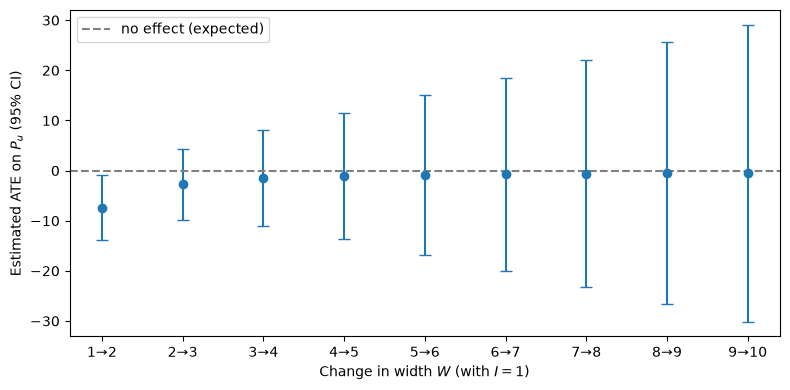

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(
    x=[f"{c}→{t}" for c, t in zip(mr2_results["W_c"], mr2_results["W_t"])],
    y=mr2_results["ate"],
    yerr=[mr2_results["ate"] - mr2_results["ci_low"], mr2_results["ci_high"] - mr2_results["ate"]],
    fmt="o",
    capsize=4,
)
ax.axhline(0, color="grey", linestyle="--", label="no effect (expected)")
ax.set_xlabel("Change in width $W$ (with $I = 1$)")
ax.set_ylabel("Estimated ATE on $P_u$ (95% CI)")
ax.legend()
plt.tight_layout()
plt.show()

For every change except the first, the confidence interval contains zero, so there's no significant effect and the
test passes. But increasing the width from **1 to 2** has a statistically significant *negative* effect on $P_u$ of
about −7.4. MR2 is violated for small windows.

### Comparing with SMT

The CTF and SMT agree: **window size affects $P_u$ for small windows, but not for larger ones**. The numbers aren't
directly comparable, though, because the two approaches test different interventions. In the SMT data the width and
height change together, whereas the CTF changes only the width. Also, SMT had 100 runs at each exact configuration, so
it can detect smaller effects, picking up a few significant differences at slightly larger window sizes. The CTF's estimates come from fewer,
general-purpose runs, so they're less precise, as shown by their wider confidence intervals.

Crucially, the CTF needed **no extra model runs** for this test. We reused the same data from MR1 to check a new
hypothesis, and could even ask a question (the effect of width alone) that the SMT data couldn't answer.

## Summary

In this tutorial we tested two metamorphic relations of the Poisson Line Tessellation model in two ways.

With **statistical metamorphic testing**, we ran the model many times at carefully chosen inputs and compared the
average outputs. This revealed that both relations break down for small windows, but needed 5000 purpose-built runs.

With **causal testing**, we followed the CTF workflow:

1. We wrote down a **causal DAG** for the model, which took little effort because its behaviour is well understood.
2. We used **identification** to confirm that neither of our test cases needed adjustment for confounders.
3. We built **regression-based estimators**, using domain knowledge (e.g. $P_u \propto I^2$) to pick the model's
   terms.
4. We ran **causal test cases** with explicit expected effects (`ExactValue` and `NoEffect`) as test oracles.

Compared with SMT, the CTF:

* **reached the same conclusions**: doubling the intensity increases $P_u$ by less than the expected factor of 4 for
  small inputs, and window size affects $P_u$ for small windows;
* **needed a fifth of the data**: 1000 general-purpose runs instead of 5000 purpose-built ones;
* **reused existing data to test a new relation**, without any further model runs.

The main cost to the tester is domain knowledge. As well as the DAG, you need a rough idea of the *shape* of the
relationships (e.g. that $P_u$ grows with $I^2$ rather than $I$) to get accurate estimates. If you're unsure of the
shape, the `LinearRegressionEstimator` also has a `gp_formula` method that uses genetic programming to search for a
suitable regression formula from the data.

## Further resources

* [Testing Causality in Scientific Modelling Software (paper)](https://dl.acm.org/doi/10.1145/3607184)
* R. Guderlei and J. Mayer, "Statistical metamorphic testing: testing programs with random output by means of statistical hypothesis tests and metamorphic testing", *QSIC 2007*, pp. 404–409.
* [Causal Testing Framework on GitHub](https://github.com/CITCOM-project/CausalTestingFramework)
* [Causal Testing Framework documentation](https://causal-testing-framework.readthedocs.io/en/latest/index.html)